# Введение в ИИ. Демоверсия 2.0 коллоквиума. Компьютерная часть

Привет! Это вторая демоверсия компьютерной части коллоквиума.

**Правила**:

* в ячейках ниже напиши или допиши код, а там, где требуется — текст;
* перед сдачей повторно выполни все ячейки;
* для сдачи загрузи в LMS своё решение в виде файла формата .ipynb.

**Можно пользоваться**:

* Google Colab или Jupyter Notebook;
* библиотеками numpy, pandas, matplotlib, seaborn и scikit-learn;
* официальной документацией к этим библиотекам: [numpy](https://numpy.org/doc/stable/), [pandas](https://pandas.pydata.org/docs/), [matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [scikit-learn](https://scikit-learn.org/stable/).

**Нельзя пользоваться**:

* другими средами разработки и библиотеками;
* нейросетями, в том числе в Colab;
* телефоном;
* посторонними вкладками, в том числе поисковыми системами;
* файлами, кроме этого ноутбука и датасетов, на которые он ссылается;
* бумажными записями;
* чужим решением.

**Решение оценивается в 0 баллов, если**:

* в коде содержится готовый ответ;
* вывод ячеек не соответствует написанному коду.

In [1]:
import matplotlib.pyplot as plt
import numpy as np


## Мёртвые души

Рассмотрим класс `Value`. Он умеет складывать и умножать числа, считать `tanh` и находить производные методом `backward`. Вычитания в нём нет, поэтому, как и на семинаре, вместо `a - b` стоит писать `a + (-b)`, а обычное число ставь справа от `*`: `w * x`, а не `x * w`.

In [2]:
import math


class Value:
    def __init__(self, data, edges=()):
        self.data = float(data)
        self.grad = 0.0
        self.edges = edges

    def __add__(self, other):
        if not isinstance(other, Value):
            other = Value(other)
        return Value(self.data + other.data,
                     edges=((self, 1.0), (other, 1.0)))

    def __mul__(self, other):
        if not isinstance(other, Value):
            other = Value(other)
        return Value(self.data * other.data,
                     edges=((self, other.data), (other, self.data)))

    def tanh(self):
        output = math.tanh(self.data)
        return Value(output, edges=((self, 1.0 - output**2),))

    def backward(self):
        order = []
        seen = set()

        def collect(node):
            if node in seen:
                return
            seen.add(node)
            for parent, _ in node.edges:
                collect(parent)
            order.append(node)

        collect(self)
        self.grad = 1.0
        for node in reversed(order):
            for parent, derivative in node.edges:
                parent.grad += node.grad * derivative

### Задание 1 [4 балла]

1. Допиши метод `relu`: он должен возвращать новый `Value` со значением $\mathrm{ReLU}(x)$ и запоминать в `edges` частную производную. В нуле считай производную равной нулю **[1 балл]**

In [5]:
def relu(self):
    # Твой код
    output = self.data if self.data > 0 else 0.0
    derivative = 1 if self.data > 0 else 0.0
    return Value(output, [(self, derivative)])


Value.relu = relu

2. Нейрон $\hat y = \mathrm{ReLU}(wx + b)$ обучается на выборке ниже. Допиши функцию `train`: она должна сделать `n_steps` шагов градиентного спуска из начальной точки `(w0, b0)` с темпом обучения `lr` и вернуть полученные `w` и `b`, а также список значений функции потерь перед каждым шагом **[1,5 балла]**

In [15]:
rng = np.random.default_rng(8)
xs = np.linspace(0.0, 2.0, 20)
ys = 2 * xs + 1 + rng.normal(0.0, 0.1, len(xs))


def mse(w, b) -> Value:
    total = Value(0.0)
    for x, y in zip(xs, ys):
        r = (w * float(x) + b).relu() + (-float(y))
        total = total + r * r
    return total * (1.0 / len(xs))


def train(w0, b0, lr, n_steps):
    w, b = Value(w0), Value(b0)
    history: list[Value] = []
    # Твой код
    for _ in range(n_steps):
        w.grad = 0
        b.grad = 0
        
        loss = mse(w, b)
        history.append(loss.data)
        
        loss.backward()
        
        w.data -= lr * w.grad
        b.data -= lr * b.grad
        
    return w.data, b.data, history

3. Запусти обучение из трёх начальных точек $(w_0, b_0)$:

$$(0{,}5;\ 0{,}5),\ (1;\ -1)\ и\ (-0{,}5;\ -0{,}5).$$

Каждый раз сделай 100 шагов с темпом обучения $0{,}05$. Выведи полученные `w` и `b` для каждой точки, а также функцию потерь на первом и последнем шаге. Историю сохрани в словарь `histories`: при помощи него ниже построй графики **[0,5 балла]**

In [17]:
starts = [(0.5, 0.5), (1.0, -1.0), (-0.5, -0.5)]
histories = {}
LR = 0.05
N_STEPS = 100

# Твой код
for n, (w0, b0) in enumerate(starts):
    w, b, history = train(w0, b0, LR, N_STEPS)
    print(f"({w0:=}, {b0:=}) -> ({w:=}, {b:=})")
    print(f"{history[0]:=} -> {history[-1]:=}")
    histories[(w0, b0)] = history


(0.5, 0.5) -> (2.0044823771935136, 1.0037680643384894)
4.904055238425289 -> 0.012024146471632215
(1.0, -1.0) -> (2.196070033725246, 0.7736644412105818)
8.423414662253455 -> 0.01401193253334892
(-0.5, -0.5) -> (-0.5, -0.5)
10.564133673209877 -> 10.564133673209877


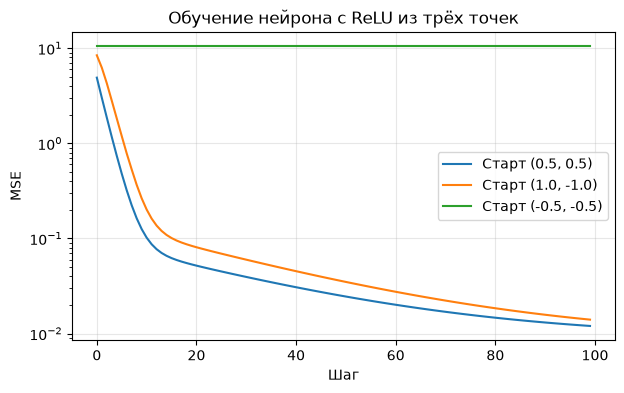

In [18]:
# Готовый код для графика, менять его не нужно
plt.figure(figsize=(7, 4))
for (w0, b0), history in histories.items():
    plt.plot(history, label=f"Старт ({w0}, {b0})")
plt.yscale("log")
plt.xlabel("Шаг")
plt.ylabel("MSE")
plt.title("Обучение нейрона с ReLU из трёх точек")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

4. Почему из второй точки нейрон обучается, а из третьей — совсем нет? **[1 балл]**

Потому что это локальный минимум